In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\NAGARAJ P\Desktop\D_T_P\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.info()
df.columns.tolist
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

(7043, 21)

In [4]:
print(df.describe)
df.head(5)

<bound method NDFrame.describe of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DS

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [6]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [7]:
features = ["tenure", "MonthlyCharges", "Contract"]
target = "Churn"

X = df[features]
y = df[target]

print(X.head())
print(y.head())

   tenure  MonthlyCharges        Contract
0       1           29.85  Month-to-month
1      34           56.95        One year
2       2           53.85  Month-to-month
3      45           42.30        One year
4       2           70.70  Month-to-month
0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: str


In [8]:
X = pd.get_dummies(
    X,
    columns=["Contract"],
    dtype=int
)

print(X.head())
print(X.columns.tolist())

   tenure  MonthlyCharges  Contract_Month-to-month  Contract_One year  \
0       1           29.85                        1                  0   
1      34           56.95                        0                  1   
2       2           53.85                        1                  0   
3      45           42.30                        0                  1   
4       2           70.70                        1                  0   

   Contract_Two year  
0                  0  
1                  0  
2                  0  
3                  0  
4                  0  
['tenure', 'MonthlyCharges', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year']


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 5)
X_test: (1409, 5)
y_train: (5634,)
y_test: (1409,)


In [10]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

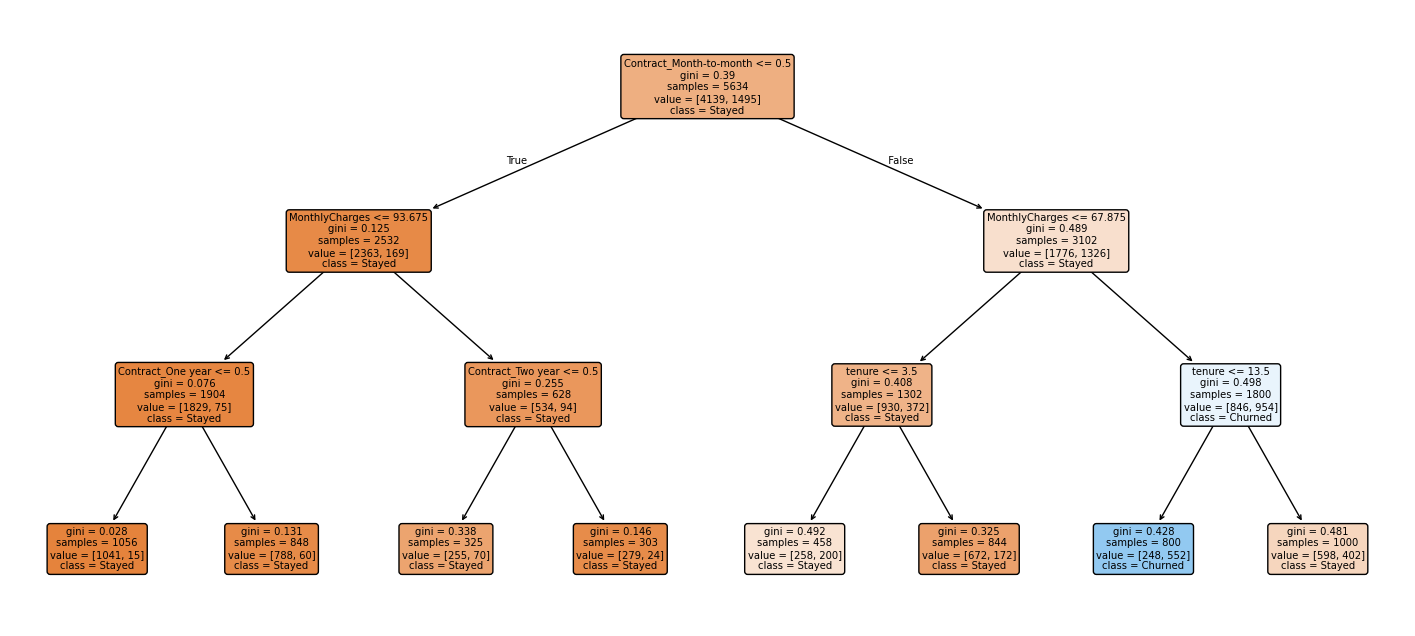

In [11]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))

plot_tree(
    model,
    feature_names=X_train.columns,
    class_names=["Stayed", "Churned"],
    filled=True,
    rounded=True
)

plt.show()

In [12]:
print("Tree depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())

Tree depth: 3
Number of leaves: 8


In [13]:
from sklearn.metrics import accuracy_score

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("Training accuracy:", accuracy_score(y_train, train_pred))
print("Testing accuracy:", accuracy_score(y_test, test_pred))

Training accuracy: 0.788604898828541
Testing accuracy: 0.7792760823278921


In [14]:
from sklearn.metrics import confusion_matrix

y_pred = model.predict(X_test)

print(confusion_matrix(y_test, y_pred))

[[965  70]
 [241 133]]


In [15]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.80      0.93      0.86      1035
         Yes       0.66      0.36      0.46       374

    accuracy                           0.78      1409
   macro avg       0.73      0.64      0.66      1409
weighted avg       0.76      0.78      0.75      1409



In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

model = DecisionTreeClassifier(
    max_depth=7,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))



from sklearn.metrics import accuracy_score

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("Training accuracy:", accuracy_score(y_train, train_pred))
print("Testing accuracy:", accuracy_score(y_test, test_pred))

              precision    recall  f1-score   support

          No       0.84      0.86      0.85      1035
         Yes       0.58      0.53      0.55       374

    accuracy                           0.77      1409
   macro avg       0.71      0.70      0.70      1409
weighted avg       0.77      0.77      0.77      1409

Training accuracy: 0.8091941782037628
Testing accuracy: 0.7743080198722498


In [17]:
from sklearn.metrics import classification_report

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("TRAINING RESULTS")
print(classification_report(y_train, train_pred))

print("TESTING RESULTS")
print(classification_report(y_test, test_pred))

TRAINING RESULTS
              precision    recall  f1-score   support

          No       0.85      0.90      0.87      4139
         Yes       0.67      0.57      0.61      1495

    accuracy                           0.81      5634
   macro avg       0.76      0.73      0.74      5634
weighted avg       0.80      0.81      0.80      5634

TESTING RESULTS
              precision    recall  f1-score   support

          No       0.84      0.86      0.85      1035
         Yes       0.58      0.53      0.55       374

    accuracy                           0.77      1409
   macro avg       0.71      0.70      0.70      1409
weighted avg       0.77      0.77      0.77      1409



In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

model = DecisionTreeClassifier(
    max_depth=7,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.90      0.68      0.78      1035
         Yes       0.47      0.78      0.59       374

    accuracy                           0.71      1409
   macro avg       0.68      0.73      0.68      1409
weighted avg       0.78      0.71      0.73      1409



In [19]:
from sklearn.metrics import confusion_matrix

y_pred = model.predict(X_test)

print(confusion_matrix(y_test, y_pred))

[[707 328]
 [ 81 293]]


In [20]:
from sklearn.metrics import classification_report

# Probability of the "Yes" class
yes_index = list(model.classes_).index("Yes")
y_proba = model.predict_proba(X_test)[:, yes_index]

# Try a threshold of 0.40
threshold = 0.40

y_pred_threshold = [
    "Yes" if probability >= threshold else "No"
    for probability in y_proba
]

print(classification_report(y_test, y_pred_threshold))

              precision    recall  f1-score   support

          No       0.92      0.64      0.76      1035
         Yes       0.46      0.84      0.60       374

    accuracy                           0.70      1409
   macro avg       0.69      0.74      0.68      1409
weighted avg       0.80      0.70      0.72      1409



In [21]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred_threshold))

[[667 368]
 [ 58 316]]


In [22]:
#Retraing the model......... 
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training rows:", len(X_train_new))
print("Validation rows:", len(X_val))

Training rows: 4507
Validation rows: 1127


In [24]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=7,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_new, y_train_new)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_feat

In [25]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

yes_index = list(model.classes_).index("Yes")
val_proba = model.predict_proba(X_val)[:, yes_index]

results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    val_pred = [
        "Yes" if p >= threshold else "No"
        for p in val_proba
    ]

    results.append({
        "Threshold": threshold,
        "Churn Precision": precision_score(
            y_val, val_pred, pos_label="Yes", zero_division=0
        ),
        "Churn Recall": recall_score(
            y_val, val_pred, pos_label="Yes", zero_division=0
        ),
        "Churn F1": f1_score(
            y_val, val_pred, pos_label="Yes", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))

   Threshold  Churn Precision  Churn Recall  Churn F1
0        0.3            0.405         0.873     0.553
1        0.4            0.455         0.823     0.586
2        0.5            0.494         0.793     0.608
3        0.6            0.514         0.719     0.600
4        0.7            0.609         0.448     0.516


In [26]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Get the probability of Churn = "Yes"
yes_index = list(model.classes_).index("Yes")
test_proba = model.predict_proba(X_test)[:, yes_index]

# Use the threshold selected from validation results
chosen_threshold = 0.30

y_test_pred = [
    "Yes" if p >= chosen_threshold else "No"
    for p in test_proba
]

print("Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=["No", "Yes"]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=["No", "Yes"]
))

Accuracy: 0.6281050390347764

Confusion Matrix:
[[554 481]
 [ 43 331]]

Classification Report:
              precision    recall  f1-score   support

          No       0.93      0.54      0.68      1035
         Yes       0.41      0.89      0.56       374

    accuracy                           0.63      1409
   macro avg       0.67      0.71      0.62      1409
weighted avg       0.79      0.63      0.65      1409



In [27]:
import pandas as pd

importance = pd.Series(
    model.feature_importances_,
    index=X_train_new.columns
).sort_values(ascending=False)

print(importance)

Contract_Month-to-month    0.550392
MonthlyCharges             0.268886
tenure                     0.163896
Contract_Two year          0.015632
Contract_One year          0.001194
dtype: float64
